<a href="https://colab.research.google.com/github/Maimoree/Datamining_capstone_Project/blob/main/Capstone3_1_6704800023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#calories-burnt-prediction

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ruchikakumbhar/calories-burnt-prediction")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'calories-burnt-prediction' dataset.
Path to dataset files: /kaggle/input/calories-burnt-prediction


In [ ]:
import os
import pandas as pd

#ตรวจสอบรายชื่อไฟล์ในโฟลเดอร์ที่ดาวน์โหลด
files = os.listdir(path)
print("Files in dataset directory:", files)

#ค้นหาและโหลดไฟล์ CSV เข้า pandas DataFrame
data_dict = {}
for file in files:
    if file.endswith('.csv'):
        file_path = os.path.join(path, file)
        df_name = file.replace('.csv', '')
        data_dict[df_name] = pd.read_csv(file_path)
        print(f"Loaded '{file}' as DataFrame name: '{df_name}' (Shape: {data_dict[df_name].shape})")

#แสดงตัวอย่างข้อมูลแรกที่มีในdict
if data_dict:
    first_key = list(data_dict.keys())[0]
    print(f"\nPreview of '{first_key}':")
    display(data_dict[first_key].head())

Files in dataset directory: ['calories.csv']
Loaded 'calories.csv' as DataFrame name: 'calories' (Shape: (15000, 9))

Preview of 'calories':


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


In [ ]:
#แถว,คอลัม
df = data_dict['calories']
df.shape

(15000, 9)

### Data Dictionary (Text Table)

```text
+------------+--------------------------------------------+------------------------+-------------------------------------------------------------+
| Column     | Description                                | Data Type              | Usage                                                       |
+------------+--------------------------------------------+------------------------+-------------------------------------------------------------+
| User_ID    | Unique identifier for each user            | Identifier             | Used for reference; should be excluded from modeling        |
| Gender     | Gender of the user                         | Categorical            | Predictive feature (requires encoding before modeling)      |
| Age        | Age of the user in years                   | Numerical - Integer    | Predictive feature                                          |
| Height     | Height of the user in centimeters          | Numerical - Continuous | Predictive feature                                          |
| Weight     | Weight of the user in kilograms            | Numerical - Continuous | Predictive feature                                          |
| Duration   | Duration of the exercise session in minutes| Numerical - Continuous | Predictive feature                                          |
| Heart_Rate | Heart rate during exercise (BPM)           | Numerical - Integer    | Predictive feature                                          |
| Body_Temp  | Body temperature during exercise (°C)      | Numerical - Continuous | Predictive feature                                          |
| Calories   | Calories burned during exercise            | Numerical - Target     | Target variable (to be predicted)                           |
+------------+--------------------------------------------+------------------------+-------------------------------------------------------------+
```

In [ ]:
#-----Clean-----

In [ ]:
#missing
df = data_dict['calories']
df.isnull().sum()

,0
User_ID,0
Gender,0
Age,0
Height,0
Weight,0
Duration,0
Heart_Rate,0
Body_Temp,0
Calories,0


In [ ]:
#เช็คoutlier
for col in df.select_dtypes(include="number").columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: {len(outliers)} Outliers")


User_ID: 0 Outliers
Age: 0 Outliers
Height: 14 Outliers
Weight: 6 Outliers
Duration: 0 Outliers
Heart_Rate: 1 Outliers
Body_Temp: 369 Outliers
Calories: 4 Outliers


In [ ]:
df_clean = df.copy()

cols = ["Age","Height","Weight","Duration","Heart_Rate","Body_Temp"]
results = []

for col in cols:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3 - Q1
    lower=Q1 - 1.5 * IQR
    upper=Q3 + 1.5 * IQR

    #นับOutlierก่อนจัดการ
    before = ((df[col] < lower) | (df[col] > upper)).sum()

    #จัดการOutlier
    df_clean[col] = df_clean[col].clip(lower, upper)

    #ตรวจOutlierหลังจัดการ
    after = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()

    results.append({
        "Column": col,
        "Before": before,
        "Managed": before,
        "Remaining": after
    })

display(pd.DataFrame(results))

print("ขนาดข้อมูลหลังจัดการ:", df_clean.shape)

,Column,Before,Managed,Remaining
0,Age,0,0,0
1,Height,14,14,0
2,Weight,6,6,0
3,Duration,0,0,0
4,Heart_Rate,1,1,0
5,Body_Temp,369,369,0


ขนาดข้อมูลหลังจัดการ: (15000, 9)


In [ ]:
#-----กราฟความสัมพันธ์Calories-----

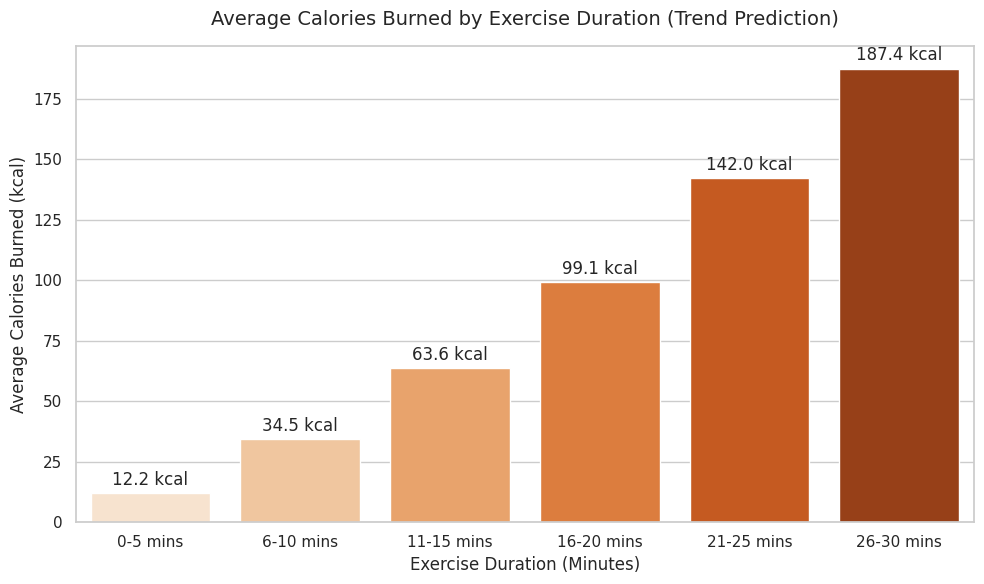

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#ระยะเวลาการออกกำลังกาย
df['Duration_Group'] = pd.cut(df['Duration'], bins=[0, 5, 10, 15, 20, 25, 30], labels=['0-5 mins', '6-10 mins', '11-15 mins', '16-20 mins', '21-25 mins', '26-30 mins'])

#คำนวณค่าเฉลี่ยของแคลอรีในแต่ละช่วงเวลา
avg_calories = df.groupby('Duration_Group', observed=False)['Calories'].mean().reset_index()

#ตั้งค่าธีมการแสดงผล
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

#สร้างกราฟแท่ง
ax = sns.barplot(x='Duration_Group', y='Calories', data=avg_calories, hue='Duration_Group', palette='Oranges', legend=False)

#เพิ่มป้ายกำกับค่าในกราฟแต่ละแท่ง
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f kcal', padding=3)

plt.title('Average Calories Burned by Exercise Duration (Trend Prediction)', fontsize=14, pad=15)
plt.xlabel('Exercise Duration (Minutes)', fontsize=12)
plt.ylabel('Average Calories Burned (kcal)', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
#-----TrainModel-----

In [ ]:
from sklearn.model_selection import train_test_split

#ตัวแปร
features = ["Gender", "Age", "Height", "Weight","Duration", "Heart_Rate", "Body_Temp"]

X = df[features]
y = df["Calories"]

#แบ่งข้อมูล80ต่อ20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (12000, 7)
Testing: (3000, 7)


In [ ]:
import numpy as np
import pandas as pd

#จัดการOutlierโดยใช้ขอบเขตจากTrainingData
numeric_cols = ["Age", "Height", "Weight","Duration", "Heart_Rate", "Body_Temp"]

for col in numeric_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)

#แปลงGenderเป็นตัวเลข(ตรวจสอบก่อนว่ามีคอลัมน์ Gender หรือไม่ เพื่อให้รันซ้ำได้)
if "Gender" in X_train.columns:
    X_train = pd.get_dummies(X_train, columns=["Gender"], drop_first=True, dtype=int)
if "Gender" in X_test.columns:
    X_test = pd.get_dummies(X_test, columns=["Gender"], drop_first=True, dtype=int)
#จัดคอลัมน์ให้ตรงกัน
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Trainโมเดลเรียบร้อย")

Trainโมเดลเรียบร้อย


In [ ]:
#เปรียบเทียบโมเดล
print("Linear Regression")
print("MAE:", mean_absolute_error(y_test, pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))
print("R2:", r2_score(y_test, pred1))

print("\nDecision Tree")
print("MAE:", mean_absolute_error(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))
print("R2:", r2_score(y_test, pred2))

print("\nRandom Forest")
print("MAE:", mean_absolute_error(y_test, pred3))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred3)))
print("R2:", r2_score(y_test, pred3))

Linear Regression
MAE: 8.450638183540628
RMSE: 11.49281088809027
R2: 0.9672716732637827

Decision Tree
MAE: 3.9507712603122855
RMSE: 5.786228353158712
R2: 0.9917041208043236

Random Forest
MAE: 1.6916733333333336
RMSE: 2.6533858432827544
R2: 0.9982554954900729


**Metric	ค่าที่ต้องการ**

MAE (Mean Absolute Error)	  

RMSE (Root Mean Square Error)

R² (R-squared / Coefficient of Determination)

เลือก random forest

In [ ]:
#-----prediction-----

In [ ]:
import pandas as pd

#เลือกRandomForestที่ฝึกแล้ว
rf = models["Random_Forest"]

#รับข้อมูลจากผู้ใช้
print("กรอกข้อมูลสำหรับทำนาย Calories")

gender = input("เพศ (Male/Female): ").strip().lower()

while gender not in ["male", "female"]:
    gender = input("กรุณากรอก Male หรือ Female: ").strip().lower()

age = float(input("อายุ (ปี): "))
height = float(input("ส่วนสูง (cm): "))
weight = float(input("น้ำหนัก (kg): "))
duration = float(input("เวลาออกกำลังกาย (นาที): "))
heart_rate = float(input("อัตราการเต้นหัวใจ: "))
body_temp = float(input("อุณหภูมิร่างกาย (°C): "))


new_data = pd.DataFrame([{
    "Age": age,
    "Height": height,
    "Weight": weight,
    "Duration": duration,
    "Heart_Rate": heart_rate,
    "Body_Temp": body_temp,
    "Gender_male": 1 if gender == "male" else 0
}])

#จัดการOutlierด้วยขอบเขตจากTrainingData
for col in ["Age", "Height", "Weight","Duration", "Heart_Rate", "Body_Temp"]:

    Q1 = df.loc[X_train.index, col].quantile(0.25)
    Q3 = df.loc[X_train.index, col].quantile(0.75)
    IQR = Q3 - Q1

    new_data[col] = new_data[col].clip(
        Q1 - 1.5 * IQR,
        Q3 + 1.5 * IQR
    )

#จัดเรียงคอลัมน์ให้ตรงกับโมเดล
new_data = new_data.reindex(
    columns=X_train.columns,
    fill_value=0
)

#ทำนายผล
prediction = rf.predict(new_data)

print("\n===== ผลการทำนาย =====")
print("Calories ที่คาดว่าจะเผาผลาญ:",
      round(prediction[0], 2), "kcal")

กรอกข้อมูลสำหรับทำนาย Calories
เพศ (Male/Female): Male
อายุ (ปี): 27
ส่วนสูง (cm): 175
น้ำหนัก (kg): 59
เวลาออกกำลังกาย (นาที): 30
อัตราการเต้นหัวใจ: 60
อุณหภูมิร่างกาย (°C): 37

===== ผลการทำนาย =====
Calories ที่คาดว่าจะเผาผลาญ: 136.12 kcal
